# Analiza turističnih trendov v Sloveniji med letoma 2018 in 2025
Analiziral sem turizem v Sloveniji po občinah med letoma 2018 in 2025. Podatki so bili zajeti iz strani https://pxweb.stat.si/SiStatData/pxweb/sl/Data/-/2164525S.px in https://pxweb.stat.si/SiStatData/pxweb/sl/Data/-/05C5003S.px ter obdelani s pomočjo pythona.

## Uvod
V seminarski nalogi so me zanimale 4 teme. Katere občine v Sloveniji so najbolj turistično obremenjene, katere občine so imele največjo turistično rast in katere največji padec iz leta 2018 v 2025, katere so najhitreje okrevale po upadu turizma med covidom ter katere občine so bile v letu 2025 najbolj obiskane s strani domačih gostov in katere iz strani tujih.

In [219]:
import pandas as pd
import matplotlib.pyplot as plt

ST_PREBIVALCEV = pd.read_csv('podatki/prebivalstvo_obcine.csv')
PRIHODI = pd.read_csv('podatki/turizem_prihodi.csv')

Najprej združimo podatke iz datotek turizem_prihodi.csv in prebivalstvo_obcine.csv v skupno tabelo.

In [220]:
pd.set_option('display.max_rows', 200)

ST_PREBIVALCEV = ST_PREBIVALCEV[ST_PREBIVALCEV['obcina'] != 'SLOVENIJA'].copy()
PRIHODI = PRIHODI[PRIHODI['obcina'] != 'SLOVENIJA'].copy()

ST_PREBIVALCEV['obcina_koda'] = ST_PREBIVALCEV['obcina'].str[:3]
ST_PREBIVALCEV['obcina_ime'] = ST_PREBIVALCEV['obcina'].str[4:]

# enak ključ za obcine
ST_PREBIVALCEV['kljuc'] = ST_PREBIVALCEV['obcina_ime'].str.lower().str.strip()
PRIHODI['kljuc'] = PRIHODI['obcina'].str.lower().str.strip()

SKUPNA_TABELA = PRIHODI.merge(
    ST_PREBIVALCEV[['kljuc', 'obcina_koda', 'leto', 'vrednost']],
    on=['kljuc', 'leto'],
)
SKUPNA_TABELA = SKUPNA_TABELA.rename(columns={'vrednost_x': 'turizem', 'vrednost_y': 'prebivalci'})

SKUPNA_TABELA

,obcina,poreklo,meritev,leto,turizem,kljuc,obcina_koda,prebivalci
0,Ajdovščina,Domači,Prihodi turistov,2018,3913.0,ajdovščina,001,19130
1,Ajdovščina,Domači,Prihodi turistov,2019,3223.0,ajdovščina,001,19249
2,Ajdovščina,Domači,Prihodi turistov,2020,4642.0,ajdovščina,001,19418
3,Ajdovščina,Domači,Prihodi turistov,2021,5949.0,ajdovščina,001,19704
4,Ajdovščina,Domači,Prihodi turistov,2022,5667.0,ajdovščina,001,19727
...,...,...,...,...,...,...,...,...
6779,Žužemberk,Tuji,Prenočitve turistov,2021,1175.0,žužemberk,193,4741
6780,Žužemberk,Tuji,Prenočitve turistov,2022,2719.0,žužemberk,193,4719
6781,Žužemberk,Tuji,Prenočitve turistov,2023,3878.0,žužemberk,193,4681
6782,Žužemberk,Tuji,Prenočitve turistov,2024,3832.0,žužemberk,193,4663


### 1. Najbolj turistično obremenjene občine
V prvi točki me je zanimalo katere občine so najbolj turistično obremenjene, torej da dobijo največ turističnega obiska glede na število prebivalcev v občini. Bolj natančno program razvrsti občine po številu prenočitev na prebivalca v občini in vzel sem povprečja čez leta od 2018 do 2025.

In [221]:
prenocitve = SKUPNA_TABELA[SKUPNA_TABELA['meritev'] == 'Prenočitve turistov'].copy()

prenocitve_skupaj = prenocitve.groupby(
    ['leto', 'obcina_koda', 'obcina', 'prebivalci'], 
    as_index = False
)['turizem'].sum()

prenocitve_skupaj = prenocitve_skupaj.rename(columns={'turizem': 'skupne prenocitve'})
prenocitve_skupaj['prenocitve na prebivalca'] = prenocitve_skupaj['skupne prenocitve'] / prenocitve_skupaj['prebivalci']

povprecja_obcine = (
    prenocitve_skupaj
    .groupby(['obcina_koda', 'obcina'], as_index=False)
    .agg({
        'skupne prenocitve': 'mean',
        'prebivalci': 'mean',
        'prenocitve na prebivalca': 'mean'
    })
)

povprecja_obcine['skupne prenocitve'] = povprecja_obcine['skupne prenocitve'].round(0).astype(int)
povprecja_obcine['prebivalci'] = povprecja_obcine['prebivalci'].round(0).astype(int)
povprecja_obcine['prenocitve na prebivalca'] = povprecja_obcine['prenocitve na prebivalca'].round(2)

top10_povprecje = (
    povprecja_obcine
    .sort_values(by='prenocitve na prebivalca', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top10_povprecje = top10_povprecje.rename(columns={
    'skupne prenocitve': 'povprecno prenocitev na leto',
    'prebivalci': 'povprecno prebivalcev',
    'prenocitve na prebivalca': 'prenocitve na prebivalca povprecje'
})

top10_povprecje[['obcina', 'povprecno prenocitev na leto', 'povprecno prebivalcev', 'prenocitve na prebivalca povprecje']]

,obcina,povprecno prenocitev na leto,povprecno prebivalcev,prenocitve na prebivalca povprecje
0,Bovec,500058,3087,162.32
1,Kranjska Gora,842835,5898,147.52
2,Bohinj,726039,5327,136.32
3,Bled,961854,8068,119.22
4,Podčetrtek,392874,3546,110.73
5,Piran/Pirano,1752967,18046,97.15
6,Ankaran/Ancarano,292834,3293,88.64
7,Moravske Toplice,511221,5914,86.44
8,Veržej,99504,1340,74.28
9,Solčava,33786,515,65.54


Iz tabele je razvidno da prva 4 mesta zasedejo občine v alpskih pokrajinah, temu pa sledijo zdraviliške destinacije in destinacije ob morju. 10. mesto presenetljivo zaseda Solčava z le dobrimi 500 prebivalci a beleži kar slabih 34000 prenočitev letno zaradi bližine popularne Logarske doline.

Spodaj sledi graf gibanja števila prenočitev na prebivalca od leta 2018 do 2025 desetih najbolj tuistično obremenjenih občin. Leta 2020 se vidi močan upad turizma zaradi izbruha epidemije virusa COVID-19 in za tem sledi približno dvoletno okrevanje do številk iz leta 2019.

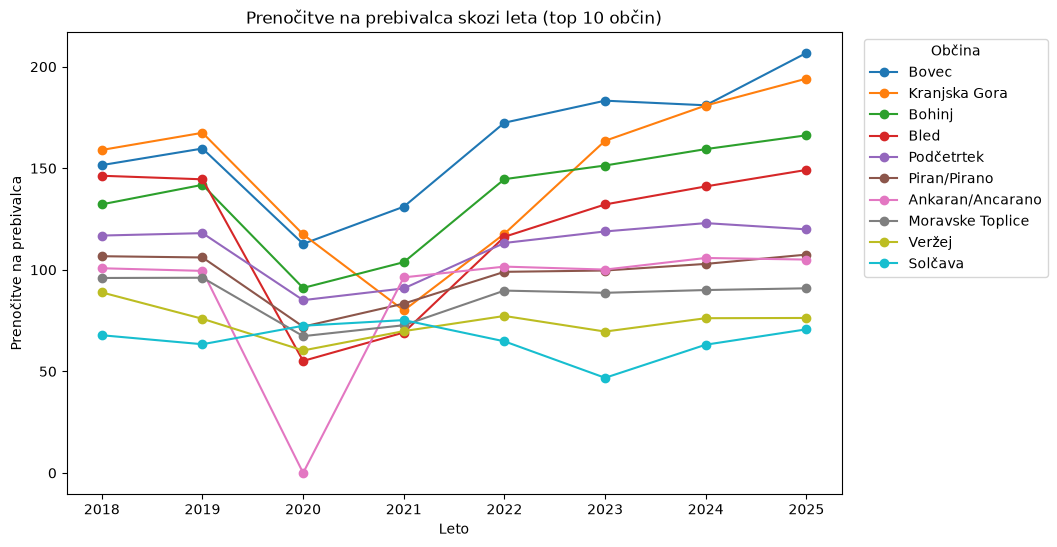

In [222]:
top_obcine = top10_povprecje['obcina'].tolist()

trend = (
    prenocitve_skupaj[prenocitve_skupaj['obcina'].isin(top_obcine)]
    .pivot(index='leto', columns='obcina', values='prenocitve na prebivalca')
    [top_obcine]
)

fig, ax = plt.subplots(figsize=(10, 6))
trend.plot(ax=ax, marker='o')

ax.set_xlabel('Leto')
ax.set_ylabel('Prenočitve na prebivalca')
ax.set_title('Prenočitve na prebivalca skozi leta (top 10 občin)')
ax.set_xticks(range(2018, 2026))
ax.legend(title='Občina', bbox_to_anchor=(1.02, 1))

plt.show()

### 2. Največja turistična rast in upad v primerjavi med letoma 2018 in 2025
V naslednji točki me je zanimalo katere občine so doživele največjo turistično rast in upad iz leta 2018 na leto 2025.

In [223]:
prenoc = SKUPNA_TABELA[SKUPNA_TABELA['meritev'] == 'Prenočitve turistov'].dropna(subset=['turizem'])

leto_obcina = prenoc.groupby(['obcina', 'leto'], as_index=False)['turizem'].sum()

rast = leto_obcina.pivot(index='obcina', columns='leto', values='turizem')[[2018, 2025]]
rast = rast.dropna()          

rast['koeficient'] = rast[2025] / rast[2018]
rast['rast_%'] = (rast['koeficient'] - 1) * 100

rast_prag = rast[rast[2018] >= 10000]

najvecja_rast = rast_prag.sort_values('koeficient', ascending=False).head(10).round(2)
najvecji_padec = rast_prag.sort_values('koeficient').head(10).round(2)

rast_tab = najvecja_rast[[2018, 2025, 'koeficient']].reset_index()
padec_tab = najvecji_padec[[2018, 2025, 'koeficient']].reset_index()

rast_tab[2018] = rast_tab[2018].astype(int)
padec_tab[2018] = padec_tab[2018].astype(int)

rast_tab[2025] = rast_tab[2025].astype(int)
padec_tab[2025] = padec_tab[2025].astype(int)

primerjava_rasti = pd.concat([rast_tab, padec_tab], axis=1, keys=['Največja rast', 'Največji padec'])
primerjava_rasti.index = range(1, 11)

primerjava_rasti

Največja rast                              Največji padec          \
leto        obcina    2018    2025 koeficient           obcina    2018   
1        Žirovnica   16091   41232       2.56             Ruše   13680   
2            Žalec   13574   33422       2.46           Cerkno   57172   
3            Pivka   10538   25762       2.44    Murska Sobota   50682   
4        Železniki   11783   25014       2.12          Medvode   35802   
5            Gorje   37377   77218       2.07          Vrhnika   21995   
6          Mozirje   32317   58857       1.82       Novo mesto  117426   
7       Radovljica  280102  503658       1.80  Rogaška Slatina  295475   
8       Ajdovščina   28709   50882       1.77           Divača   26339   
9         Mislinja   18878   32539       1.72          Šoštanj  118251   
10           Tržič   16440   28051       1.71  Renče - Vogrsko   20440   

                         
leto    2025 koeficient  
1       5768       0.42  
2      26101       0.46  
3      23770       0.47  
4      18525       0.52  
5      13195       0.60  
6      71919       0.61  
7     195231       0.66  
8      19584       0.74  
9      88545       0.75  
10     16462       0.81

Prvo mesto zaseda občina Žirovnica, ki v svoji turistični ponudbi ponuja Pot kulturne dediščine Žirovnica, ki povezuje rojstne hiše pomembnih osebnosti v slovenski literaturi (France Prešeren, Matija Čop, Fran Saleški Finžgar, Janez Jalen), obenem pa služi tudi izhodišče za izlete s kolesi in pohodništvo v Karavankah.

Na drugem mestu sledi Žalec, komur pri tem turističnem uspehu izjemno pripomore znana fontana piva Zeleno zlato, ki letos praznuje že svojo 10. obletnico in je v tem času privabila že okoli 1,2 milijona obiskovalcev. Še ena atrakcija pa je turistična pešpot Od hmelja do piva - 5,5 kilometra dolga krožna pot, ki povezuje hmeljarsko dediščino te regije z drugimi naravnimi lepotami. K uspehu pa nedvomno pripomore tudi tranzitna lega ob avtocesti med Ljubljano in Mariborom.

Pri preostalih občinah v prvi deseterici je rast turizma verjetno posledica več dejavnikov. Več občin leži v bližini že uveljavljenih turističnih krajev (Gorje in Radovljica ob Bledu in Bohinju, Pivka ob Postojni), zato se turisti vse pogosteje odločajo za nastanitev v sosednjih, cenejših in manj obremenjenih krajih. K temu pripomorejo tudi lokalne znamenitosti, kot so Vintgar v Gorjah, Mozirski gaj v Mozirju, Park vojaške zgodovine v Pivki ali Vipavska dolina pri Ajdovščini. Pomembno vlogo ima verjetno tudi povečevanje števila nastanitev (apartmaji, turistične kmetije), saj imajo majhne občine z nizkim izhodiščem že ob nekaj novih ponudnikih velik odstotni skok.

Pri občinah z največjim padcem prenočitev je padec pogosto povezan s covidom: pri Rogaški Slatini, Novem mestu in Medvodah se je število prenočitev po 2020 sicer delno okrepilo, a ravni iz 2018 niso več dosegle. Pri nekaterih občinah (Cerkno, Murska Sobota, Divača) pa se je upadanje nadaljevalo tudi v zadnjih letih po covidu. Padec je verjetno tudi posledica manjše ponudbe, na primer zaprtja ali prenove večjega nastanitvenega objekta, kar pri manjših občinah hitro vpliva na celotno število prenočitev. Pri mestnih občinah, kot sta Novo mesto in Murska Sobota, so imeli lahko vpliv tudi manjše število poslovnih obiskov in tranzitnih gostov.

Spodaj sledi še grafični prikaz rasti in padca turizma.

Tu sem dodal zahtevo, da mora imeti občina vsaj 10000 nočitev v letu 2018, saj bi majhne občine z manj kot 1000 prebivalci lahko dosegale izjemno visoke koeficiente četudi se število turistov ne bi objektivno veliko spremenilo.

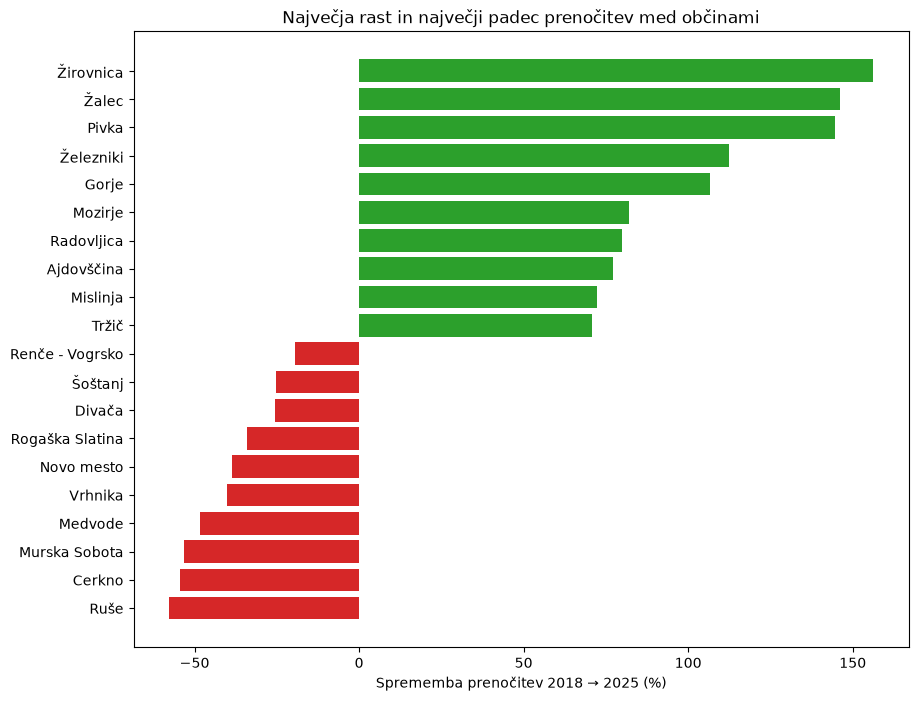

In [224]:
top = rast_prag.sort_values('koeficient', ascending=False).head(10)
dno = rast_prag.sort_values('koeficient').head(10)

prikaz = pd.concat([top, dno.sort_values('koeficient', ascending=False)])

barve = ['tab:green' if x >= 0 else 'tab:red' for x in prikaz['rast_%']]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(prikaz.index, prikaz['rast_%'], color=barve)
ax.invert_yaxis()

ax.set_xlabel('Sprememba prenočitev 2018 → 2025 (%)')
ax.set_title('Največja rast in največji padec prenočitev med občinami')

plt.show()

### 3. Hitrost okrevanja po upadu turizma med COVIDOM
Leta 2020 je svet zadela epidemija virusa COVID-19, ki je povzročila zaprtja meja in močno omejitev turizma. Zanimalo me je katere občine so si po tem upadu turizma najhitreje opomogle.

In [225]:
leta = [2020, 2021, 2022, 2023, 2024, 2025]

prenocitve_tuji = SKUPNA_TABELA[
    (SKUPNA_TABELA['meritev'] == 'Prenočitve turistov') &
    (SKUPNA_TABELA['poreklo'] == 'Tuji')
].dropna(subset=['turizem'])

leto_obcina = prenocitve_tuji.groupby(['obcina', 'leto'], as_index=False)['turizem'].sum()
tabela = leto_obcina.pivot(index='obcina', columns='leto', values='turizem')

tabela = tabela[tabela[2019] >= 10000]

dosegel = tabela[leta].ge(tabela[2019], axis=0)
tabela['okrevanje'] = dosegel.idxmax(axis=1).where(dosegel.any(axis=1))

# občine, ki so okrevale, urejene po letu okrevanja
okrevale = tabela[tabela['okrevanje'].notna()].sort_values('okrevanje')

vrstice = []
for obcina in okrevale.index:
    leto = int(okrevale.loc[obcina, 'okrevanje'])
    vrstice.append({
        'občina': obcina,
        'leto okrevanja': leto,
        'prenočitve 2019': int(okrevale.loc[obcina, 2019]),
        'prenočitve v letu okrevanja': int(okrevale.loc[obcina, leto])
    })

lestvica = pd.DataFrame(vrstice)
lestvica

,občina,leto okrevanja,prenočitve 2019,prenočitve v letu okrevanja
0,Krško,2021,11925,11975
1,Žalec,2021,11938,13990
2,Brda,2022,31822,34358
3,Ajdovščina,2022,22645,29610
4,Cerknica,2022,14689,14970
5,Idrija,2022,12992,13324
6,Hajdina,2022,13096,13720
7,Bohinj,2022,554385,574507
8,Ilirska Bistrica,2022,11897,12992
9,Hoče - Slivnica,2022,23618,31381


Iz rezultatov je razvidno, da so po večini občine potrebovale več kot dve leti, da so se vrnile na raven turizma iz leta 2019 kar je za mnoge domačine, ki se s tem poklicno ukvarjajo katastrofalno. Zanimivo pa je, da za občine, ki zasegajo najvišja mesta v tabeli marsikdo ne bi pričakoval tam, saj ne slovijo kot najbolj 'turistične' občine. 

Dodal sem zahtevo, da mora biti število nočitev leta 2019 vsaj 10000, saj bi drugače male občine z manj kot 5000 prebivalci dominirale lestvico ampak pri svojem okrevanju niso potrebovale doseči tako velikih številk kot velike občine.

### 4. Najbolj 'tuje' in 'domače' občine
V zadnji točki me je zanimalo za katere občine v Sloveniji v letu 2025 največji delež turističnega obiska predstavljajo domači gostje in v katerih tuji.

In [226]:
p = SKUPNA_TABELA[
    (SKUPNA_TABELA['meritev'] == 'Prenočitve turistov') &
    (SKUPNA_TABELA['leto'] == 2025)
].dropna(subset=['turizem'])

t = p.pivot_table(index='obcina', columns='poreklo', values='turizem', aggfunc='sum')

t['skupaj'] = t['Domači'] + t['Tuji']
t = t[t['skupaj'] >= 10000]
t['delez_tujih'] = t['Tuji'] / t['skupaj'] * 100

najbolj_tuje = t.sort_values('delez_tujih', ascending=False).head(10)
najbolj_domace = t.sort_values('delez_tujih').head(10)

najbolj_tuje[['Domači', 'Tuji', 'delez_tujih']].round(0)
tuje = najbolj_tuje[['Domači', 'Tuji', 'delez_tujih']].round(0).reset_index()
domace = najbolj_domace[['Domači', 'Tuji', 'delez_tujih']].round(0).reset_index()

tuje['Domači'] = tuje['Domači'].astype(int)
tuje['Tuji'] = tuje['Tuji'].astype(int)

domace['Domači'] = domace['Domači'].astype(int)
domace['Tuji'] = domace['Tuji'].astype(int)

primerjava = pd.concat([tuje, domace], axis=1, keys=['Najbolj tuje', 'Najbolj domače'])
primerjava.index = range(1, 11)

primerjava

Najbolj tuje                                  Najbolj domače          \
poreklo       obcina  Domači     Tuji delez_tujih             obcina  Domači   
1         Radovljica   14887   488771        97.0  Šmarješke Toplice  103249   
2               Bled   43563  1172761        96.0           Mislinja   27708   
3          Ljubljana  113619  2730510        96.0   Selnica ob Dravi    8518   
4            Medvode     899    17626        95.0             Dobrna   96552   
5              Pivka    1299    24463        95.0             Veržej   87157   
6          Brezovica     910    16620        95.0             Kostel    9130   
7             Šenčur    1878    31861        94.0  Dolenjske Toplice   99162   
8            Domžale    2948    49956        94.0              Semič   10821   
9           Postojna   10629   159872        94.0           Črnomelj   36573   
10             Bovec   43270   577851        93.0           Ljutomer   50370   

                            
poreklo   Tuji delez_tujih  
1        17473        14.0  
2         4831        15.0  
3         1570        16.0  
4        18834        16.0  
5        18051        17.0  
6         2240        20.0  
7        30126        23.0  
8         3464        24.0  
9        11733        24.0  
10       18303        27.0

V rezultatu je vidno, da so mesta v katerih dominirajo tuji gostje locirana ob najbolj znanih turističnih atrakcijah v Sloveniji in pa ob glavnih prometnih povezavah v Sloveniji. Po drugi strani pa so občine v katerih prevladujejo domači gostje predvsem občine s ponudbo zdraviliškega turizma.

# Zaključek
Analiza podatkov potrjuje, da turizem v Sloveniji ostaja ena najpomembnejših gospodarskih panog, ki po epidemiji COVID-19 doživlja močan ponovni vzpon. Rast turizma prinaša številne pozitivne učinke, kot so ustvarjanje novih delovnih mest, pritok dohodkov v lokalna gospodarstva ter dodatna sredstva za obnovo in zaščito kulturne ter naravne dediščine za prihodnje generacije.

Vendar pa porast obiska – predvsem v najbolj prepoznavnih destinacijah – odpira tudi izzive prekomernega turizma. V občinah, kot so Ljubljana, Piran, Bled in Bohinj, se vse pogosteje pojavlja nezadovoljstvo lokalnega prebivalstva. Glavni razlogi za nezadovoljstvo lokalnega prebivalstva do turistov so:
- stanovanjska kriza: v prestolnici in obalnih krajih se velik delež stanovanj spreminja v apartmaje za kratkoročni turistični najem (npr. prek platforme Airbnb), kar drastično zvišuje cene nepremičnin in najemnin ter je razlog za selitev prebivalstva iz mestnega središča. To je pripeljalo do tega, da je država na seznam, kjer bo oddajanje turistom strožje omejeno, uvrstila 14 najbolj obremenjenih občin.
- gneča: ceste, javni promet in parkirišča na Bledu, v Bohinju ter na obali med sezono težko obvladujejo naval obiskovalcev.
- visoke cene: mnoge domačine moti, da se ponudba v centrih mest (lokali, trgovine) skoraj v celoti prilagaja tujim gostom, cene pa s tem postajajo lokalnemu prebivalstvu nedostopne.